In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

path = glob.glob("../data/*.csv")[0]
df = pd.read_csv(path)
print(path)
print(df.shape)
df.head()

../data\paysim.csv
(6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [2]:
print(df.dtypes)
print(df.isna().sum())

step                int64
type                  str
amount            float64
nameOrig              str
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest              str
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dtype: object
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64


In [3]:
n_fraud = int(df["isFraud"].sum())
print(f"Fraud rows: {n_fraud:,} of {len(df):,} ({df['isFraud'].mean():.4%})")
print(f"Accuracy of a model that always says 'not fraud': {1 - df['isFraud'].mean():.4%}")

Fraud rows: 8,213 of 6,362,620 (0.1291%)
Accuracy of a model that always says 'not fraud': 99.8709%


In [4]:
df.groupby("type")["isFraud"].agg(count="count", frauds="sum", rate="mean")

,count,frauds,rate
type,,,
CASH_IN,1399284,0,0.000000
CASH_OUT,2237500,4116,0.001840
DEBIT,41432,0,0.000000
PAYMENT,2151495,0,0.000000
TRANSFER,532909,4097,0.007688


In [5]:
df.groupby("type")["isFraud"].agg(count="count", frauds="sum", rate="mean")

,count,frauds,rate
type,,,
CASH_IN,1399284,0,0.000000
CASH_OUT,2237500,4116,0.001840
DEBIT,41432,0,0.000000
PAYMENT,2151495,0,0.000000
TRANSFER,532909,4097,0.007688


             count          mean           std   min         25%        50%  \
isFraud                                                                       
0        6354407.0  1.781970e+05  5.962370e+05  0.01   13368.395   74684.72   
1           8213.0  1.467967e+06  2.404253e+06  0.00  127091.330  441423.44   

                75%          max  
isFraud                           
0         208364.76  92445516.64  
1        1517771.48  10000000.00  


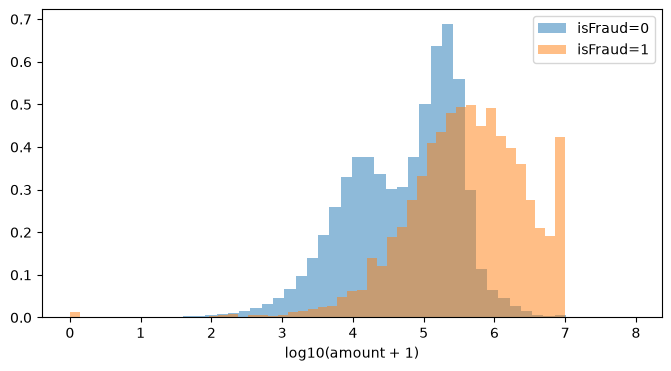

In [6]:
print(df.groupby("isFraud")["amount"].describe())

fig, ax = plt.subplots(figsize=(8, 4))
for label, g in df.groupby("isFraud"):
    ax.hist(np.log10(g["amount"] + 1), bins=50, alpha=0.5, density=True, label=f"isFraud={label}")
ax.set_xlabel("log10(amount + 1)")
ax.legend()
plt.show()

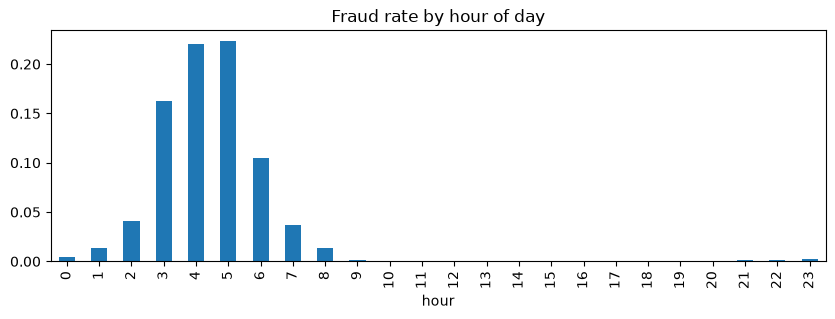

In [7]:
df["hour"] = df["step"] % 24
df.groupby("hour")["isFraud"].mean().plot(kind="bar", figsize=(10, 3), title="Fraud rate by hour of day")
plt.show()

In [8]:
df["orig_emptied"] = (df["newbalanceOrig"] == 0) & (df["oldbalanceOrg"] > 0)
df.groupby("orig_emptied")["isFraud"].agg(count="count", rate="mean")

,count,rate
orig_emptied,,
False,4842039,0.000042
True,1520581,0.005269


## Dataset notes
- PaySim is synthetic, so it is not real PayPal data.
- It has amount, transaction type, time (step) and account balances, but no country or currency.
- Country and currency will be simulated and labelled as simulated everywhere.
- Fraud is very rare, so I'll evaluate with PR-AUC, precision and recall, not accuracy.

In [9]:
sub = df[df["type"].isin(["TRANSFER", "CASH_OUT"])].copy()
print(f"{len(sub):,} rows, {int(sub['isFraud'].sum()):,} frauds ({sub['isFraud'].mean():.3%})")

2,770,409 rows, 8,213 frauds (0.296%)


In [10]:
sub["amount_eq_balance"] = np.isclose(sub["amount"], sub["oldbalanceOrg"])
sub["orig_emptied"] = (sub["newbalanceOrig"] == 0) & (sub["oldbalanceOrg"] > 0)
for col in ["amount_eq_balance", "orig_emptied"]:
    print(sub.groupby(col)["isFraud"].agg(count="count", frauds="sum", rate="mean"), "\n")

                     count  frauds      rate
amount_eq_balance                           
False              2762372     179  0.000065
True                  8037    8034  0.999627 

                count  frauds      rate
orig_emptied                           
False         1582335     201  0.000127
True          1188074    8012  0.006744 



In [11]:
sub["amount_eq_balance"] = np.isclose(sub["amount"], sub["oldbalanceOrg"])
sub["orig_emptied"] = (sub["newbalanceOrig"] == 0) & (sub["oldbalanceOrg"] > 0)
for col in ["amount_eq_balance", "orig_emptied"]:
    print(sub.groupby(col)["isFraud"].agg(count="count", frauds="sum", rate="mean"), "\n")

                     count  frauds      rate
amount_eq_balance                           
False              2762372     179  0.000065
True                  8037    8034  0.999627 

                count  frauds      rate
orig_emptied                           
False         1582335     201  0.000127
True          1188074    8012  0.006744 



In [12]:
sub["period"] = pd.cut(sub["step"], bins=[0, 200, 400, 600, 744])
sub.groupby("period", observed=True)["isFraud"].agg(count="count", frauds="sum", rate="mean")

,count,frauds,rate
period,,,
"(0, 200]",1045328,2254,0.002156
"(200, 400]",1484208,2223,0.001498
"(400, 600]",197323,2136,0.010825
"(600, 744]",43550,1600,0.036739


Note: Fraud only in TRANSFER and CASH_OUT, the 10M cap, and the balance features that PayPal events lack.

## Modelling

In [13]:
sub = df[df["type"].isin(["TRANSFER", "CASH_OUT"])].copy()
sub = sub.sort_values("step").reset_index(drop=True)

# Features a PayPal event can supply
sub["is_transfer"] = (sub["type"] == "TRANSFER").astype(int)
sub["hour"] = sub["step"] % 24
sub["log_amount"] = np.log1p(sub["amount"])

# Benchmark-only features (PayPal events do not carry balances)
sub["orig_emptied"] = ((sub["newbalanceOrig"] == 0) & (sub["oldbalanceOrg"] > 0)).astype(int)
sub["amount_eq_balance"] = np.isclose(sub["amount"], sub["oldbalanceOrg"]).astype(int)
sub["orig_delta_err"] = sub["oldbalanceOrg"] - sub["amount"] - sub["newbalanceOrig"]
sub["dest_delta_err"] = sub["oldbalanceDest"] + sub["amount"] - sub["newbalanceDest"]

DEPLOY = ["log_amount", "is_transfer", "hour"]
BENCH = DEPLOY + ["orig_emptied", "amount_eq_balance", "orig_delta_err", "dest_delta_err",
                  "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]
print(len(sub), "rows")

2770409 rows


In [14]:
q60, q80 = sub["step"].quantile([0.6, 0.8])
train = sub[sub["step"] <= q60]
val = sub[(sub["step"] > q60) & (sub["step"] <= q80)]
test = sub[sub["step"] > q80]
for name, part in [("train", train), ("val", val), ("test", test)]:
    print(f"{name}: {len(part):,} rows, {int(part['isFraud'].sum()):,} frauds ({part['isFraud'].mean():.3%})")

train: 1,672,907 rows, 3,193 frauds (0.191%)
val: 544,998 rows, 762 frauds (0.140%)
test: 552,504 rows, 4,258 frauds (0.771%)


In [15]:
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

def evaluate(name, y, p):
    ap = average_precision_score(y, p)
    auc = roc_auc_score(y, p)
    prec, rec, _ = precision_recall_curve(y, p)
    r50 = rec[prec >= 0.5].max() if (prec >= 0.5).any() else 0.0
    r90 = rec[prec >= 0.9].max() if (prec >= 0.9).any() else 0.0
    print(f"{name}: PR-AUC={ap:.4f} (random={y.mean():.4f}) ROC-AUC={auc:.4f} "
          f"recall@prec50={r50:.3f} recall@prec90={r90:.3f}")
    return ap

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier

def fit_lr(cols):
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
    return m.fit(train[cols], train["isFraud"])

def fit_gb(cols):
    m = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=42)
    return m.fit(train[cols], train["isFraud"])

models = {}
for label, cols in [("deployable", DEPLOY), ("benchmark", BENCH)]:
    for mname, fit in [("logreg", fit_lr), ("hist_gb", fit_gb)]:
        models[(label, mname)] = fit(cols)
        p = models[(label, mname)].predict_proba(val[cols])[:, 1]
        evaluate(f"VAL {label:10s} {mname:8s}", val["isFraud"], p)

VAL deployable logreg  : PR-AUC=0.0070 (random=0.0014) ROC-AUC=0.7794 recall@prec50=0.000 recall@prec90=0.000
VAL deployable hist_gb : PR-AUC=0.2130 (random=0.0014) ROC-AUC=0.7939 recall@prec50=0.231 recall@prec90=0.161
VAL benchmark  logreg  : PR-AUC=0.9993 (random=0.0014) ROC-AUC=1.0000 recall@prec50=1.000 recall@prec90=0.999
VAL benchmark  hist_gb : PR-AUC=0.9960 (random=0.0014) ROC-AUC=1.0000 recall@prec50=1.000 recall@prec90=1.000


In [17]:
import joblib, os

final_key = ("deployable", "hist_gb")
final = models[final_key]

p_test = final.predict_proba(test[DEPLOY])[:, 1]
evaluate("TEST final", test["isFraud"], p_test)

p_val = final.predict_proba(val[DEPLOY])[:, 1]
os.makedirs("../models", exist_ok=True)
joblib.dump({
    "model": final,
    "features": DEPLOY,
    "version": "v1-paysim-deployable",
    "val_score_quantiles": np.quantile(p_val, np.linspace(0, 1, 1001)),
}, "../models/risk_model_v1.joblib")
print("saved")

TEST final: PR-AUC=0.3002 (random=0.0077) ROC-AUC=0.8009 recall@prec50=0.289 recall@prec90=0.000
saved


## Notes
- PaySim is synthetic, so metrics measure the simulation, not real fraud.
- The deployable model uses amount, type and hour. The hour pattern is probably a simulation artifact, because PaySim fraud isn’t tied to the daily activity cycle.
- The benchmark model with balances shows how much the missing balance fields cost.
- Split: train on earlier time, test on later time. Reported PR-AUC, precision and recall, not accuracy.

In [18]:
p_test = final.predict_proba(test[DEPLOY])[:, 1]
y = test["isFraud"].values
order = np.argsort(-p_test)
for pct in [0.5, 1, 2, 5, 10]:
    k = int(len(y) * pct / 100)
    caught = y[order[:k]].sum()
    print(f"Review top {pct}% ({k:,} payments): catches {caught / y.sum():.1%} of frauds, precision {caught / k:.1%}")

Review top 0.5% (2,762 payments): catches 30.0% of frauds, precision 46.2%
Review top 1% (5,525 payments): catches 37.6% of frauds, precision 29.0%
Review top 2% (11,050 payments): catches 42.8% of frauds, precision 16.5%
Review top 5% (27,625 payments): catches 53.3% of frauds, precision 8.2%
Review top 10% (55,250 payments): catches 62.7% of frauds, precision 4.8%


In [19]:
from sklearn.ensemble import HistGradientBoostingClassifier

variants = {
    "with hour": ["log_amount", "is_transfer", "hour"],
    "without hour": ["log_amount", "is_transfer"],
}
fitted = {}
for name, cols in variants.items():
    m = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=42)
    m.fit(train[cols], train["isFraud"])
    p = m.predict_proba(val[cols])[:, 1]
    evaluate(f"VAL {name:13s}", val["isFraud"], p)
    fitted[name] = (m, cols)

VAL with hour    : PR-AUC=0.2130 (random=0.0014) ROC-AUC=0.7939 recall@prec50=0.231 recall@prec90=0.161
VAL without hour : PR-AUC=0.0056 (random=0.0014) ROC-AUC=0.6482 recall@prec50=0.000 recall@prec90=0.000


In [20]:
import joblib, os

DEPLOY = ["log_amount", "is_transfer"]
final = fitted["without hour"][0]

evaluate("TEST final", test["isFraud"], final.predict_proba(test[DEPLOY])[:, 1])

p_val = final.predict_proba(val[DEPLOY])[:, 1]
os.makedirs("../models", exist_ok=True)
joblib.dump({
    "model": final,
    "features": DEPLOY,
    "version": "v2-paysim-deployable-no-hour",
    "val_score_quantiles": np.quantile(p_val, np.linspace(0, 1, 1001)),
}, "../models/risk_model_v2.joblib")
print("saved v2")

TEST final: PR-AUC=0.0332 (random=0.0077) ROC-AUC=0.6395 recall@prec50=0.013 recall@prec90=0.000
saved v2


In [21]:
print(train["amount"].quantile([0.01, 0.05, 0.10]))

0.01     3538.1038
0.05    17365.5030
0.10    34140.4540
Name: amount, dtype: float64


In [1]:
import glob
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

# Rebuild the same data and time split used for training
path = glob.glob("../data/*.csv")[0]
d = pd.read_csv(path, usecols=["step", "type", "amount", "isFraud"])
d = d[d["type"].isin(["TRANSFER", "CASH_OUT"])].sort_values("step").reset_index(drop=True)
d["is_transfer"] = (d["type"] == "TRANSFER").astype(int)
d["log_amount"] = np.log1p(d["amount"])
d["hour"] = d["step"] % 24
q60, q80 = d["step"].quantile([0.6, 0.8])
val = d[(d["step"] > q60) & (d["step"] <= q80)]
test = d[d["step"] > q80]

# Load the saved v2 model
bundle = joblib.load("../models/risk_model_v2.joblib")
model, feats = bundle["model"], bundle["features"]
print("model:", bundle["version"], "| features:", feats)

def report(name, part):
    y = part["isFraud"].values
    p = model.predict_proba(part[feats])[:, 1]
    prec, rec, _ = precision_recall_curve(y, p)
    r50 = rec[prec >= 0.5].max() if (prec >= 0.5).any() else 0.0
    print(f"{name}: PR-AUC={average_precision_score(y, p):.4f} "
          f"(random baseline={y.mean():.4f}) ROC-AUC={roc_auc_score(y, p):.4f} "
          f"recall at 50% precision={r50:.3f}")
    order = np.argsort(-p)
    for pct in [1, 5]:
        k = int(len(y) * pct / 100)
        print(f"   review top {pct}% -> catches {y[order[:k]].sum() / y.sum():.1%} of frauds")

report("VALIDATION", val)
report("TEST", test)

model: v2-paysim-deployable-no-hour | features: ['log_amount', 'is_transfer']
VALIDATION: PR-AUC=0.0056 (random baseline=0.0014) ROC-AUC=0.6482 recall at 50% precision=0.000
   review top 1% -> catches 1.7% of frauds
   review top 5% -> catches 15.9% of frauds
TEST: PR-AUC=0.0332 (random baseline=0.0077) ROC-AUC=0.6395 recall at 50% precision=0.013
   review top 1% -> catches 8.4% of frauds
   review top 5% -> catches 24.4% of frauds
